# ID6105 Assignment 04
**Madhav Pradeep (ME24B038)**

Graphs are stored as `{vertex: set(neighbours)}` unless stated otherwise. `networkx` is used
only to cross check a few results, never to do the work asked for.

In [1]:
%matplotlib inline
import math
import time
import random
import itertools
from collections import deque, defaultdict

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(6105)

## Problem 1: Preliminaries

The proofs are in the report. The claims are checked here on random graphs.

In [2]:
def random_simple_graph(n, p, seed):
    r = np.random.default_rng(seed)
    adj = {v: set() for v in range(n)}
    for u in range(n):
        for v in range(u + 1, n):
            if r.random() < p:
                adj[u].add(v)
                adj[v].add(u)
    return adj


def degrees(adj):
    return {v: len(nb) for v, nb in adj.items()}


def is_connected(adj):
    """BFS from any vertex."""
    start = next(iter(adj))
    seen, q = {start}, deque([start])
    while q:
        u = q.popleft()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                q.append(v)
    return len(seen) == len(adj)


bad_odd = bad_repeat = bad_conn = 0
for s in range(300):
    n = int(np.random.default_rng(s).integers(2, 25))
    adj = random_simple_graph(n, 0.3, s)
    deg = degrees(adj)
    if sum(1 for d in deg.values() if d % 2) % 2:          # (a) even count of odd degrees
        bad_odd += 1
    if len(set(deg.values())) == n:                        # (b) two vertices of equal degree
        bad_repeat += 1
    m = sum(deg.values()) // 2                             # (e) dense graphs are connected
    if m > (n - 1) * (n - 2) // 2 and not is_connected(adj):
        bad_conn += 1
print("counterexamples found over 300 random graphs:",
      f"(a) {bad_odd}, (b) {bad_repeat}, (e) {bad_conn}")

counterexamples found over 300 random graphs: (a) 0, (b) 0, (e) 0


## Problem 2: Graph to adjacency matrix and back

In [3]:
def graph_to_matrix(V, E):
    idx = {v: i for i, v in enumerate(V)}
    A = np.zeros((len(V), len(V)), dtype=int)
    for u, v in E:
        A[idx[u], idx[v]] = A[idx[v], idx[u]] = 1
    return A


def matrix_to_graph(A, V=None):
    n = len(A)
    V = list(range(n)) if V is None else list(V)
    E = [(V[i], V[j]) for i in range(n) for j in range(i + 1, n) if A[i][j]]
    return V, E


def complete_graph(k):
    V = list(range(k))
    return V, [(i, j) for i in range(k) for j in range(i + 1, k)]


print(f"{'graph':>6} {'n':>3} {'m':>4} {'n(n-1)/2':>9} {'round trip ok':>14} {'regular':>8}")
for k in [4, 5, 6, 10]:
    V, E = complete_graph(k)
    A = graph_to_matrix(V, E)
    V2, E2 = matrix_to_graph(A, V)
    deg = A.sum(1)
    print(f"{'K'+str(k):>6} {len(V):>3} {len(E):>4} {k*(k-1)//2:>9}"
          f" {str(sorted(E2) == sorted(E)):>14} {str(sorted({int(d) for d in deg})):>8}")
print()
print("adjacency matrix of K4:")
print(graph_to_matrix(*complete_graph(4)))

 graph   n    m  n(n-1)/2  round trip ok  regular
    K4   4    6         6           True      [3]
    K5   5   10        10           True      [4]
    K6   6   15        15           True      [5]
   K10  10   45        45           True      [9]

adjacency matrix of K4:
[[0 1 1 1]
 [1 0 1 1]
 [1 1 0 1]
 [1 1 1 0]]


The Heawood graph is the LCF graph $[5,-5]^7$: a 14-cycle plus one chord per vertex,
alternately to the vertex 5 ahead and 5 behind.

n, m        : 14 21
degrees     : [3]
round trip  : True
matches nx  : True
bipartite   : True  girth: 6


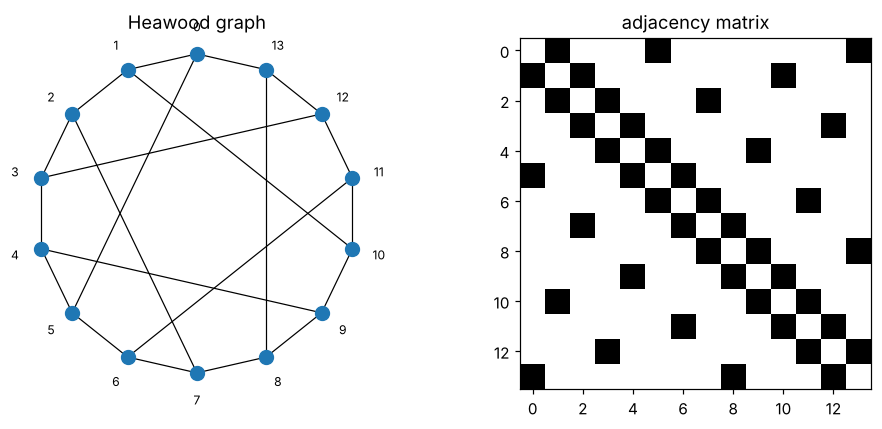

In [4]:
def heawood():
    n = 14
    V = list(range(n))
    E = {tuple(sorted((i, (i + 1) % n))) for i in range(n)}       # the rim
    for i in range(n):
        E.add(tuple(sorted((i, (i + (5 if i % 2 == 0 else -5)) % n))))
    return V, sorted(E)


V, E = heawood()
A = graph_to_matrix(V, E)
V2, E2 = matrix_to_graph(A, V)
print("n, m        :", len(V), len(E))
print("degrees     :", sorted({int(d) for d in A.sum(1)}))
print("round trip  :", sorted(E2) == sorted(E))
print("matches nx  :", nx.is_isomorphic(nx.Graph(E), nx.heawood_graph()))
print("bipartite   :", nx.is_bipartite(nx.Graph(E)), " girth:", nx.girth(nx.Graph(E)))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
pos = {i: (math.cos(2*math.pi*i/14 + math.pi/2), math.sin(2*math.pi*i/14 + math.pi/2)) for i in range(14)}
for u, v in E:
    ax[0].plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], "k-", lw=0.8)
for i, (x, y) in pos.items():
    ax[0].plot(x, y, "o", color="tab:blue", ms=9)
    ax[0].text(1.17*x, 1.17*y, str(i), ha="center", va="center", fontsize=8)
ax[0].set_aspect("equal"); ax[0].axis("off"); ax[0].set_title("Heawood graph")
ax[1].imshow(A, cmap="Greys"); ax[1].set_title("adjacency matrix")
plt.tight_layout(); plt.savefig("fig1_heawood.png"); plt.show()

## Problem 3: Six degrees of separation on a Facebook ego-network

`facebook_combined.txt` is the combined ego-network set from the SNAP collection
(https://snap.stanford.edu/data/ego-Facebook.html): 4039 users, 88234 friendships.

In [5]:
def read_edgelist(path):
    adj = defaultdict(set)
    with open(path) as f:
        for line in f:
            if line.strip():
                u, v = (int(x) for x in line.split()[:2])
                adj[u].add(v)
                adj[v].add(u)
    return dict(adj)


def bfs_distances(adj, src):
    dist = {src: 0}
    q = deque([src])
    while q:
        u = q.popleft()
        for v in adj[u]:
            if v not in dist:
                dist[v] = dist[u] + 1
                q.append(v)
    return dist


fb = read_edgelist("facebook_combined.txt")
n = len(fb)
m = sum(len(s) for s in fb.values()) // 2
deg = np.array([len(s) for s in fb.values()])
print(f"nodes {n}, edges {m}")
print(f"(a) average degree = 2m/n = {2*m/n:.3f}   (max {deg.max()}, median {int(np.median(deg))})")
print("    connected:", is_connected(fb))

nodes 4039, edges 88234
(a) average degree = 2m/n = 43.691   (max 1045, median 25)
    connected: True


In [6]:
# (b) 2000 random pairs, own BFS
verts = list(fb)
r = random.Random(6105)
t0 = time.perf_counter()
samples = []
for _ in range(2000):
    u, v = r.sample(verts, 2)
    samples.append(bfs_distances(fb, u)[v])
samples = np.array(samples)
print(f"(b) average separation over 2000 random pairs: {samples.mean():.3f}"
      f"  (sampling took {time.perf_counter()-t0:.1f} s)")

(b) average separation over 2000 random pairs: 3.693  (sampling took 20.1 s)


In [7]:
# exact distribution over all pairs: the same BFS, run from every vertex by scipy (in C)
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

order = sorted(fb)
pos = {v: i for i, v in enumerate(order)}
rows = [pos[u] for u in order for v in fb[u]]
cols = [pos[v] for u in order for v in fb[u]]
Afb = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
D = shortest_path(Afb, method="D", unweighted=True, directed=False)

# cross check against the hand written BFS from three sources
for s in order[:3]:
    mine = bfs_distances(fb, s)
    assert all(mine[v] == D[pos[s], pos[v]] for v in order), "mismatch"
print("hand written BFS agrees with the all pairs matrix")

iu = np.triu_indices(n, 1)
allpairs = D[iu].astype(int)
total = allpairs.size
print(f"all {total} pairs: average separation {allpairs.mean():.3f}, diameter {allpairs.max()}")

hand written BFS agrees with the all pairs matrix


all 8154741 pairs: average separation 3.693, diameter 8


distance      pairs  fraction
       1      88234    0.0108
       2    1358067    0.1665
       3    1990926    0.2441
       4    2930780    0.3594
       5    1282585    0.1573
       6     338607    0.0415
       7     157732    0.0193
       8       7810    0.0010

mean   3.693
std    1.194
median 4.0
fraction of pairs within 6 hops: 0.9797


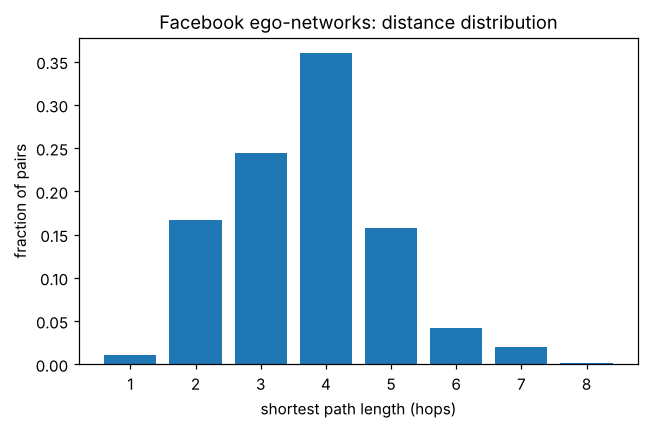

In [8]:
# (c), (d)
d_vals = np.arange(1, allpairs.max() + 1)
freq = np.array([(allpairs == d).sum() for d in d_vals])
print(f"{'distance':>8} {'pairs':>10} {'fraction':>9}")
for d, c in zip(d_vals, freq):
    print(f"{d:>8} {c:>10} {c/total:>9.4f}")

print(f"\nmean   {allpairs.mean():.3f}")
print(f"std    {allpairs.std():.3f}")
print(f"median {np.median(allpairs):.1f}")
print(f"fraction of pairs within 6 hops: {(allpairs <= 6).sum()/total:.4f}")

plt.bar(d_vals, freq/total, color="tab:blue")
plt.xlabel("shortest path length (hops)"); plt.ylabel("fraction of pairs")
plt.title("Facebook ego-networks: distance distribution")
plt.tight_layout(); plt.savefig("fig2_fb_hist.png"); plt.show()

## Problem 4: Connectedness of Erdos-Renyi graphs, and percolation

In [9]:
def er_adjacency(n, p, r):
    """G(n, p) as adjacency lists, built from the upper triangle."""
    iu = np.triu_indices(n, 1)
    mask = r.random(iu[0].size) < p
    adj = {v: [] for v in range(n)}
    for u, v in zip(iu[0][mask], iu[1][mask]):
        adj[u].append(v)
        adj[v].append(u)
    return adj


def connected_bfs(adj):
    seen, q = {0}, deque([0])
    while q:
        u = q.popleft()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                q.append(v)
    return len(seen) == len(adj)


ns = [100, 200, 400, 700, 1000]
cs = np.linspace(0.5, 2.0, 11)            # p = c ln(n)/n
frac = {}
for n in ns:
    row = []
    for c in cs:
        p = c * math.log(n) / n
        r = np.random.default_rng(hash((n, round(c, 3))) % 2**32)
        row.append(sum(connected_bfs(er_adjacency(n, p, r)) for _ in range(30)) / 30)
    frac[n] = row
    print(f"n = {n:>4}: " + " ".join(f"{x:4.2f}" for x in row))
print("c       : " + " ".join(f"{c:4.2f}" for c in cs))

n =  100: 0.00 0.00 0.17 0.33 0.50 0.87 0.90 1.00 0.97 1.00 1.00
n =  200: 0.00 0.03 0.07 0.27 0.53 0.77 0.87 1.00 0.97 0.97 1.00


n =  400: 0.00 0.00 0.03 0.33 0.53 0.80 0.93 0.97 1.00 1.00 1.00


n =  700: 0.00 0.00 0.00 0.23 0.50 0.73 0.97 0.97 1.00 1.00 1.00


n = 1000: 0.00 0.00 0.00 0.27 0.73 0.90 1.00 0.93 1.00 1.00 1.00
c       : 0.50 0.65 0.80 0.95 1.10 1.25 1.40 1.55 1.70 1.85 2.00


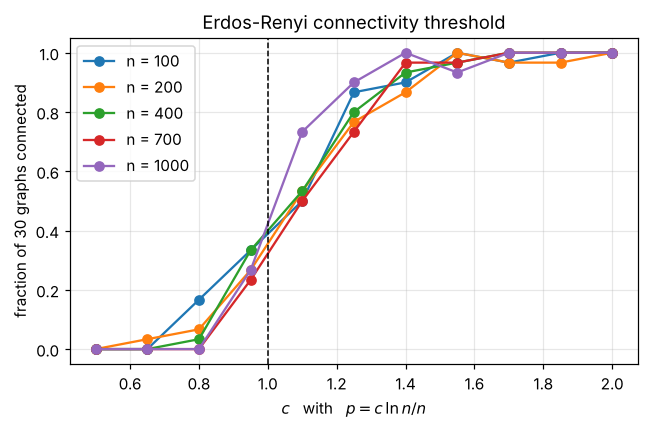

In [10]:
for n in ns:
    plt.plot(cs, frac[n], "o-", label=f"n = {n}")
plt.axvline(1.0, color="k", ls="--", lw=1)
plt.xlabel(r"$c$   with   $p = c\,\ln n / n$"); plt.ylabel("fraction of 30 graphs connected")
plt.title("Erdos-Renyi connectivity threshold"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig3_er.png"); plt.show()

### Percolation on an $N \times N$ lattice

In [11]:
def percolates(grid):
    """BFS from every open site of the top row, looking for the bottom row."""
    N = len(grid)
    seen = np.zeros_like(grid, dtype=bool)
    q = deque()
    for c in range(N):
        if grid[0, c]:
            seen[0, c] = True
            q.append((0, c))
    while q:
        i, j = q.popleft()
        if i == N - 1:
            return True, seen
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            a, b = i + di, j + dj
            if 0 <= a < N and 0 <= b < N and grid[a, b] and not seen[a, b]:
                seen[a, b] = True
                q.append((a, b))
    return False, seen


N = 100
ps = np.round(np.arange(0.40, 0.705, 0.025), 3)
pfrac = []
for p in ps:
    r = np.random.default_rng(int(p * 1000))
    pfrac.append(sum(percolates(r.random((N, N)) < p)[0] for _ in range(30)) / 30)
    print(f"p = {p:.3f}: fraction percolating = {pfrac[-1]:.2f}")

p = 0.400: fraction percolating = 0.00
p = 0.425: fraction percolating = 0.00
p = 0.450: fraction percolating = 0.00
p = 0.475: fraction percolating = 0.00
p = 0.500: fraction percolating = 0.00
p = 0.525: fraction percolating = 0.00
p = 0.550: fraction percolating = 0.00
p = 0.575: fraction percolating = 0.27
p = 0.600: fraction percolating = 0.63


p = 0.625: fraction percolating = 0.90
p = 0.650: fraction percolating = 1.00
p = 0.675: fraction percolating = 1.00


p = 0.700: fraction percolating = 1.00


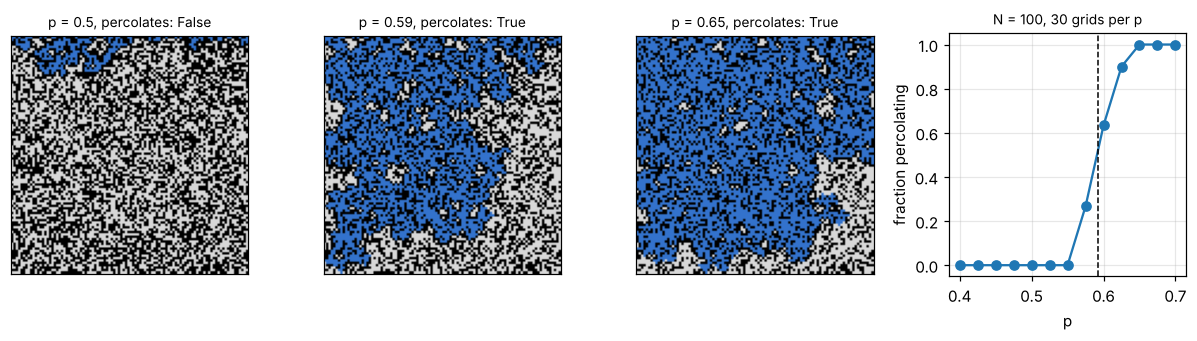

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(11, 3.2))
for a, p in zip(ax[:3], [0.50, 0.59, 0.65]):
    g = np.random.default_rng(6105).random((N, N)) < p
    ok, seen = percolates(g)
    img = np.zeros((N, N, 3))
    img[g] = [0.85, 0.85, 0.85]           # open
    img[seen] = [0.20, 0.45, 0.80]        # reachable from the top
    a.imshow(img); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"p = {p}, percolates: {ok}", fontsize=9)
ax[3].plot(ps, pfrac, "o-")
ax[3].axvline(0.5927, color="k", ls="--", lw=1)
ax[3].set_xlabel("p"); ax[3].set_ylabel("fraction percolating"); ax[3].grid(alpha=0.3)
ax[3].set_title("N = 100, 30 grids per p", fontsize=9)
plt.tight_layout(); plt.savefig("fig4_percolation.png"); plt.show()

## Problem 5: The chip network (`Edges.txt`)

2903 nodes, 8095 weighted undirected edges.

In [13]:
def read_weighted(path):
    adj = defaultdict(dict)
    edges = []
    with open(path) as f:
        for line in f:
            if line.strip():
                a, b, w = line.split()
                u, v, w = int(a), int(b), float(w)
                adj[u][v] = adj[v][u] = w
                edges.append((u, v, w))
    return dict(adj), edges


chip, chip_edges = read_weighted("Edges.txt")
print("nodes", len(chip), " edges", len(chip_edges))


def components(adj):
    seen, comps = set(), []
    for s in adj:
        if s in seen:
            continue
        comp, q = {s}, deque([s])
        seen.add(s)
        while q:
            u = q.popleft()
            for v in adj[u]:
                if v not in seen:
                    seen.add(v); comp.add(v); q.append(v)
        comps.append(comp)
    return comps


comps = components(chip)
print("(a) connected:", len(comps) == 1, "| components:", len(comps),
      "| largest:", max(len(c) for c in comps))

nodes 2903  edges 8095
(a) connected: True | components: 1 | largest: 2903


### (b) Minimum spanning tree (Kruskal with union-find)

In [14]:
class DSU:
    def __init__(self, items):
        self.p = {x: x for x in items}
        self.r = {x: 0 for x in items}

    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.r[ra] < self.r[rb]:
            ra, rb = rb, ra
        self.p[rb] = ra
        self.r[ra] += self.r[ra] == self.r[rb]
        return True


def kruskal(nodes, edges):
    dsu = DSU(nodes)
    tree = [e for e in sorted(edges, key=lambda e: e[2]) if dsu.union(e[0], e[1])]
    return tree


mst = kruskal(list(chip), chip_edges)
print(f"MST edges  : {len(mst)}  (n - 1 = {len(chip)-1})")
print(f"MST weight : {sum(w for _, _, w in mst):.4f}")
print(f"lightest, heaviest edge in the tree: {mst[0][2]:.6g}, {mst[-1][2]:.6g}")
G_chk = nx.Graph(); G_chk.add_weighted_edges_from(chip_edges)
print("networkx check:", f"{nx.minimum_spanning_tree(G_chk).size(weight='weight'):.4f}")

MST edges  : 2902  (n - 1 = 2902)
MST weight : 18.7290
lightest, heaviest edge in the tree: 0.000446056, 0.0594741
networkx check: 18.7290


### (c) Dijkstra from the highest-degree node

In [15]:
import heapq


def dijkstra(adj, src):
    dist = {src: 0.0}
    prev = {}
    pq = [(0.0, src)]
    done = set()
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)
        for v, w in adj[u].items():
            nd = d + w
            if nd < dist.get(v, math.inf):
                dist[v] = nd
                prev[v] = u
                heapq.heappush(pq, (nd, v))
    return dist, prev


deg = {v: len(nb) for v, nb in chip.items()}
hub = min((v for v in chip if deg[v] == max(deg.values())))
print(f"highest degree node: {hub} (degree {deg[hub]})")

dist, prev = dijkstra(chip, hub)
d = np.array(list(dist.values()))
print(f"reached {len(dist)} of {len(chip)} nodes")
print(f"weighted distance: mean {d.mean():.4f}, median {np.median(d):.4f}, max {d.max():.4f}")
far = max(dist, key=lambda v: dist[v])
print(f"farthest node overall: {far} at {dist[far]:.4f}")

deg3 = [v for v in chip if deg[v] == 3]
target = max(deg3, key=lambda v: dist[v])
print(f"(d) farthest degree-3 node: {target} at distance {dist[target]:.4f} "
      f"({len(deg3)} nodes have degree 3)")

path, cur = [target], target
while cur != hub:
    cur = prev[cur]
    path.append(cur)
print("path from hub:", " -> ".join(map(str, path[::-1][:8])), "... total hops", len(path) - 1)

highest degree node: 242 (degree 6)
reached 2903 of 2903 nodes
weighted distance: mean 0.2819, median 0.2876, max 0.6382
farthest node overall: 207 at 0.6382
(d) farthest degree-3 node: 224 at distance 0.5490 (10 nodes have degree 3)
path from hub: 242 -> 466 -> 450 -> 451 -> 452 -> 676 -> 900 -> 916 ... total hops 37


### (d) Maximum flow from the hub to that node (Edmonds-Karp)

In [16]:
def edmonds_karp(adj, s, t):
    """Each undirected edge becomes two arcs of the same capacity."""
    cap = defaultdict(dict)
    for u in adj:
        for v, w in adj[u].items():
            cap[u][v] = w
    flow = 0.0
    while True:
        parent = {s: None}
        q = deque([s])
        while q and t not in parent:
            u = q.popleft()
            for v, c in cap[u].items():
                if c > 1e-12 and v not in parent:
                    parent[v] = u
                    q.append(v)
        if t not in parent:
            return flow
        # bottleneck along the augmenting path
        v, b = t, math.inf
        while parent[v] is not None:
            b = min(b, cap[parent[v]][v]); v = parent[v]
        v = t
        while parent[v] is not None:
            u = parent[v]
            cap[u][v] -= b
            cap[v][u] = cap[v].get(u, 0.0) + b
            v = u
        flow += b


t0 = time.perf_counter()
mf = edmonds_karp(chip, hub, target)
print(f"max flow {hub} -> {target}: {mf:.6f}   ({time.perf_counter()-t0:.1f} s)")
print(f"capacity leaving the hub  : {sum(chip[hub].values()):.6f}")
print(f"capacity entering {target}: {sum(chip[target].values()):.6f}")
print("networkx check:", f"{nx.maximum_flow_value(G_chk, hub, target, capacity='weight'):.6f}")

max flow 242 -> 224: 0.074343   (0.0 s)
capacity leaving the hub  : 0.223028
capacity entering 224: 0.074343


networkx check: 0.074343


## Problem 7: Scheduling the test rig

In [17]:
DUR = dict(A=3, B=2, C=1, D=1, E=1, F=1, G=4, H=2, I=1, J=2, K=1, L=1, M=1)
PRE = dict(A=[], B=[], C=["A", "B"], D=["C"], E=["C"], F=["D", "E"], G=[],
           H=["D", "G"], I=["H"], J=["E"], K=["I", "J"], L=["H"], M=["F", "K", "L"])
PRE_BAD = {k: list(v) for k, v in PRE.items()}
PRE_BAD["C"] = ["A", "B", "L"]                     # the extra spreadsheet line


def build(pre):
    succ = {v: [] for v in pre}
    for v, ps in pre.items():
        for p in ps:
            succ[p].append(v)
    return {v: sorted(s) for v, s in succ.items()}


succ_bad = build(PRE_BAD)
print("(a) adjacency list (u -> tasks that need u):")
for v in sorted(succ_bad):
    print(f"    {v} -> {succ_bad[v] if succ_bad[v] else '-'}")

(a) adjacency list (u -> tasks that need u):
    A -> ['C']
    B -> ['C']
    C -> ['D', 'E']
    D -> ['F', 'H']
    E -> ['F', 'J']
    F -> ['M']
    G -> ['H']
    H -> ['I', 'L']
    I -> ['K']
    J -> ['K']
    K -> ['M']
    L -> ['C', 'M']
    M -> -


In [18]:
def dfs_three_colour(succ):
    colour = {v: "white" for v in succ}
    parent, order, back = {}, [], []

    def visit(u):
        colour[u] = "grey"
        for v in succ[u]:
            if colour[v] == "white":
                parent[v] = u
                visit(v)
            elif colour[v] == "grey" and not back:
                cyc, x = [], u                      # rebuild the cycle v ... u v
                while x != v:
                    cyc.append(x); x = parent[x]
                back.append(((u, v), [v] + cyc[::-1] + [v]))
        colour[u] = "black"
        order.append(u)

    for s in sorted(succ):
        if colour[s] == "white":
            visit(s)
    return order, back


order, back = dfs_three_colour(succ_bad)
(edge, cycle) = back[0]
print(f"(b) first edge into a grey vertex: {edge[0]} -> {edge[1]}")
print("    cycle closed:", " -> ".join(cycle))

(b) first edge into a grey vertex: L -> C
    cycle closed: C -> D -> H -> L -> C


In [19]:
def kahn(succ):
    """Ready tasks are kept sorted, so the alphabetically smallest is released first."""
    indeg = {v: 0 for v in succ}
    for u in succ:
        for v in succ[u]:
            indeg[v] += 1
    ready = sorted(v for v in succ if indeg[v] == 0)
    out = []
    while ready:
        u = ready.pop(0)
        out.append(u)
        for v in succ[u]:
            indeg[v] -= 1
            if indeg[v] == 0:
                ready.append(v)
        ready.sort()
    return out, [v for v in sorted(succ) if v not in out]


done, left = kahn(succ_bad)
print("(c) Kahn releases:", done)
print("    left over    :", left, f"({len(left)} tasks)")
print("    DFS cycle    :", cycle[:-1], f"({len(cycle)-1} tasks)")

(c) Kahn releases: ['A', 'B', 'G']
    left over    : ['C', 'D', 'E', 'F', 'H', 'I', 'J', 'K', 'L', 'M'] (10 tasks)
    DFS cycle    : ['C', 'D', 'H', 'L'] (4 tasks)


### (d) Topological orders of the corrected graph

In [20]:
succ = build(PRE)
order, back = dfs_three_colour(succ)
print("cycles after deleting L -> C:", back)
dfs_order = order[::-1]
kahn_order, _ = kahn(succ)
print("(i)  DFS reverse finishing order :", dfs_order)
print("(ii) Kahn, alphabetically ready  :", kahn_order)
print("same order:", dfs_order == kahn_order)


def valid_topological(seq, pre):
    at = {v: i for i, v in enumerate(seq)}
    return all(at[p] < at[v] for v in pre for p in pre[v])


print("both valid:", valid_topological(dfs_order, PRE), valid_topological(kahn_order, PRE))

cycles after deleting L -> C: []
(i)  DFS reverse finishing order : ['G', 'B', 'A', 'C', 'E', 'J', 'D', 'H', 'L', 'I', 'K', 'F', 'M']
(ii) Kahn, alphabetically ready  : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M']
same order: False
both valid: True True


### (e) Earliest start, earliest finish, critical path

In [21]:
ES, EF = {}, {}
for v in kahn_order:
    ES[v] = max((EF[p] for p in PRE[v]), default=0)
    EF[v] = ES[v] + DUR[v]
T = max(EF.values())

LF, LS = {}, {}
for v in reversed(kahn_order):
    LF[v] = min((LS[s] for s in succ[v]), default=T)
    LS[v] = LF[v] - DUR[v]

print(f"{'task':>5} {'dur':>4} {'ES':>3} {'EF':>3} {'LS':>3} {'LF':>3} {'slack':>6}")
for v in sorted(DUR):
    print(f"{v:>5} {DUR[v]:>4} {ES[v]:>3} {EF[v]:>3} {LS[v]:>3} {LF[v]:>3} {LS[v]-ES[v]:>6}")
print(f"\nminimum project duration: {T} days")
crit = [v for v in sorted(DUR) if LS[v] == ES[v]]
print("zero slack tasks:", crit)

# longest path by dynamic programming over the topological order
best, pred = {}, {}
for v in kahn_order:
    cands = [(best[p], p) for p in PRE[v]]
    b, p = max(cands) if cands else (0, None)
    best[v], pred[v] = b + DUR[v], p
end = max(best, key=best.get)
path, cur = [], end
while cur:
    path.append(cur); cur = pred[cur]
print("critical path:", " -> ".join(path[::-1]), f"= {best[end]} days")

 task  dur  ES  EF  LS  LF  slack
    A    3   0   3   0   3      0
    B    2   0   2   1   3      1
    C    1   3   4   3   4      0
    D    1   4   5   4   5      0
    E    1   4   5   5   6      1
    F    1   5   6   8   9      3
    G    4   0   4   1   5      1
    H    2   5   7   5   7      0
    I    1   7   8   7   8      0
    J    2   5   7   6   8      1
    K    1   8   9   8   9      0
    L    1   7   8   8   9      1
    M    1   9  10   9  10      0

minimum project duration: 10 days
zero slack tasks: ['A', 'C', 'D', 'H', 'I', 'K', 'M']
critical path: A -> C -> D -> H -> I -> K -> M = 10 days


### (f) Counting the valid topological orders

In [22]:
def count_topological(pre):
    """Subset DP: f[S] = number of ways to schedule exactly the task set S."""
    tasks = sorted(pre)
    idx = {v: i for i, v in enumerate(tasks)}
    need = [sum(1 << idx[p] for p in pre[v]) for v in tasks]
    full = (1 << len(tasks)) - 1
    f = [0] * (full + 1)
    f[0] = 1
    for S in range(full + 1):
        if not f[S]:
            continue
        for i in range(len(tasks)):
            if not (S >> i) & 1 and (need[i] & S) == need[i]:
                f[S | (1 << i)] += f[S]
    return f[full]


t0 = time.perf_counter()
print("distinct topological orders:", count_topological(PRE),
      f"  ({time.perf_counter()-t0:.2f} s)")
print("orders of the 13 tasks with no constraints at all:", math.factorial(13))

distinct topological orders: 2588   (0.00 s)
orders of the 13 tasks with no constraints at all: 6227020800


## Problem 8: One mesh, several graphs

In [23]:
TRI = [(0,1,5),(0,5,4),(1,2,6),(1,6,5),(2,3,7),(2,7,6),(4,5,9),(4,9,8),
       (6,7,11),(6,11,10),(8,9,13),(8,13,12),(9,10,14),(9,14,13),(10,11,15),(10,15,14)]


def node_graph(tris):
    adj = defaultdict(set)
    for t in tris:
        for u, v in itertools.combinations(t, 2):
            adj[u].add(v); adj[v].add(u)
    return dict(sorted(adj.items()))


Gn = node_graph(TRI)
nn = len(Gn)
mm = sum(len(s) for s in Gn.values()) // 2
print(f"(a) n = {nn}, m = {mm}")
print("    degrees:", {v: len(s) for v, s in Gn.items()})
print(f"    handshake: sum of degrees = {sum(len(s) for s in Gn.values())} = 2m = {2*mm}")

(a) n = 16, m = 32
    degrees: {0: 3, 1: 4, 2: 4, 3: 2, 4: 4, 5: 5, 6: 6, 7: 4, 8: 4, 9: 6, 10: 5, 11: 4, 12: 2, 13: 4, 14: 4, 15: 3}
    handshake: sum of degrees = 64 = 2m = 64


In [24]:
c = len(components(Gn))
mu = mm - nn + c
print(f"(b) components c = {c}, cyclomatic number mu = m - n + c = {mm} - {nn} + {c} = {mu}")
print(f"    triangles in the mesh: {len(TRI)}")
tris_in_graph = sum(1 for a, b, cc in itertools.combinations(sorted(Gn), 3)
                    if b in Gn[a] and cc in Gn[a] and cc in Gn[b])
print(f"    3-cliques in the node graph: {tris_in_graph}")

# the same mesh without the hole: add the two triangles of the middle square
TRI_FULL = TRI + [(5,6,10),(5,10,9)]
Gf = node_graph(TRI_FULL)
mf = sum(len(s) for s in Gf.values()) // 2
print(f"    without the hole: n = {len(Gf)}, m = {mf}, mu = {mf - len(Gf) + 1}")

(b) components c = 1, cyclomatic number mu = m - n + c = 32 - 16 + 1 = 17
    triangles in the mesh: 16
    3-cliques in the node graph: 16
    without the hole: n = 16, m = 33, mu = 18


In [25]:
def laplacian(adj):
    order = sorted(adj)
    pos = {v: i for i, v in enumerate(order)}
    L = np.zeros((len(order), len(order)))
    for u in order:
        L[pos[u], pos[u]] = len(adj[u])
        for v in adj[u]:
            L[pos[u], pos[v]] = -1
    return L, order


L, order = laplacian(Gn)
ev = np.linalg.eigvalsh(L)
print("(c) eigenvalues of L:", np.round(ev, 4))
print(f"    zero eigenvalues: {(np.abs(ev) < 1e-9).sum()}  (algebraic connectivity {ev[1]:.4f})")

TRI_DAM = [t for i, t in enumerate(TRI) if i not in (2, 3, 12, 13)]
Gd = node_graph(TRI_DAM)
Ld, order_d = laplacian(Gd)
evd = np.linalg.eigvalsh(Ld)
print(f"\n    damaged mesh: n = {len(Gd)} (nodes still used), m = "
      f"{sum(len(s) for s in Gd.values())//2}")
print("    eigenvalues:", np.round(evd, 4))
print(f"    zero eigenvalues: {(np.abs(evd) < 1e-9).sum()}")
print("    components:", [sorted(c) for c in components(Gd)])
print("    nodes that lost every element:", sorted(set(range(16)) - set(Gd)))

(c) eigenvalues of L: [-0.      0.592   1.1769  1.3211  2.6032  3.2933  3.382   4.2421  4.5703
  4.8544  5.2616  5.618   5.8855  6.3194  6.9504  7.9298]
    zero eigenvalues: 1  (algebraic connectivity 0.5920)

    damaged mesh: n = 16 (nodes still used), m = 26
    eigenvalues: [0.     0.     0.7186 0.7186 2.2679 2.2679 3.2281 3.2281 4.     4.
 4.5125 4.5125 5.5408 5.5408 5.7321 5.7321]
    zero eigenvalues: 2
    components: [[0, 1, 4, 5, 8, 9, 12, 13], [2, 3, 6, 7, 10, 11, 14, 15]]
    nodes that lost every element: []


In [26]:
def dual_graph(tris):
    adj = {i: set() for i in range(len(tris))}
    for i, j in itertools.combinations(range(len(tris)), 2):
        if len(set(tris[i]) & set(tris[j])) == 2:          # a shared side
            adj[i].add(j); adj[j].add(i)
    return adj


Gdual = dual_graph(TRI)
md_ = sum(len(s) for s in Gdual.values()) // 2
print(f"(d) dual graph: n = {len(Gdual)}, m = {md_}")
print("    degrees:", {i: len(s) for i, s in Gdual.items()})
print(f"    independent cycles: mu = {md_} - {len(Gdual)} + {len(components(Gdual))} = "
      f"{md_ - len(Gdual) + len(components(Gdual))}")


def bipartite(adj):
    colour = {}
    for s in adj:
        if s in colour:
            continue
        colour[s] = 0
        q = deque([s])
        while q:
            u = q.popleft()
            for v in adj[u]:
                if v not in colour:
                    colour[v] = 1 - colour[u]; q.append(v)
                elif colour[v] == colour[u]:
                    return False, (u, v)
    return True, None


print("    node graph bipartite :", bipartite(Gn))
print("    dual graph bipartite :", bipartite(Gdual))

(d) dual graph: n = 16, m = 16
    degrees: {0: 2, 1: 2, 2: 2, 3: 2, 4: 1, 5: 3, 6: 2, 7: 2, 8: 2, 9: 2, 10: 3, 11: 1, 12: 2, 13: 2, 14: 2, 15: 2}
    independent cycles: mu = 16 - 16 + 1 = 1
    node graph bipartite : (False, (1, 5))
    dual graph bipartite : (True, None)


### (e) Bandwidth reduction (Cuthill-McKee)

In [27]:
def structured_mesh(k):
    """k by k nodes, every square cut along the same diagonal."""
    tris = []
    for r in range(k - 1):
        for c in range(k - 1):
            a, b = r*k + c, r*k + c + 1
            d, e = (r+1)*k + c, (r+1)*k + c + 1
            tris += [(a, b, e), (a, e, d)]
    return tris


def bandwidth(adj):
    return max(abs(u - v) for u in adj for v in adj[u])


def relabel(adj, perm):
    """perm[i] = old label of the node that becomes i."""
    new = {i: set() for i in range(len(perm))}
    where = {old: i for i, old in enumerate(perm)}
    for u in adj:
        for v in adj[u]:
            new[where[u]].add(where[v])
    return new


def cuthill_mckee(adj):
    deg = {v: len(s) for v, s in adj.items()}
    start = min(adj, key=lambda v: (deg[v], v))
    seen, out, q = {start}, [], deque([start])
    while q:
        u = q.popleft()
        out.append(u)
        for v in sorted(adj[u], key=lambda v: (deg[v], v)):
            if v not in seen:
                seen.add(v); q.append(v)
    for v in sorted(adj):                       # any leftover component
        if v not in seen:
            seen.add(v); out.append(v)
    return out


k = 31
Gs = node_graph(structured_mesh(k))
perm = np.random.default_rng(6105).permutation(k * k)
Grand = relabel(Gs, list(perm))
print(f"mesh {k}x{k}: n = {len(Gs)}, m = {sum(len(s) for s in Gs.values())//2}")
print("bandwidth, natural numbering :", bandwidth(Gs))
print("bandwidth, random numbering  :", bandwidth(Grand))
Gcm = relabel(Grand, cuthill_mckee(Grand))
print("bandwidth, Cuthill-McKee     :", bandwidth(Gcm))

mesh 31x31: n = 961, m = 2760
bandwidth, natural numbering : 32
bandwidth, random numbering  : 938
bandwidth, Cuthill-McKee     : 31


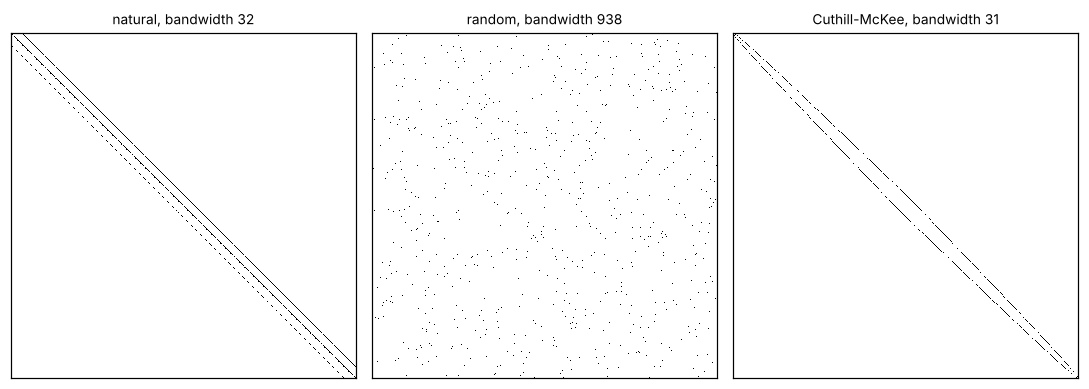

In [28]:
def spy(adj, ax, title):
    n = len(adj)
    A = np.zeros((n, n))
    for u in adj:
        for v in adj[u]:
            A[u, v] = 1
    ax.imshow(A, cmap="Greys", interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])


fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
spy(Gs, ax[0], f"natural, bandwidth {bandwidth(Gs)}")
spy(Grand, ax[1], f"random, bandwidth {bandwidth(Grand)}")
spy(Gcm, ax[2], f"Cuthill-McKee, bandwidth {bandwidth(Gcm)}")
plt.tight_layout(); plt.savefig("fig5_bandwidth.png"); plt.show()

## Problem 9: Inspecting a truss

In [29]:
def warren(k):
    E = [(f"b{i}", f"b{i+1}") for i in range(k)]
    E += [(f"t{i}", f"t{i+1}") for i in range(k - 1)]
    for i in range(k):
        E += [(f"t{i}", f"b{i}"), (f"t{i}", f"b{i+1}")]
    return E


def pratt(k):
    E = [(f"b{i}", f"b{i+1}") for i in range(k)]
    E += [(f"t{i}", f"t{i+1}") for i in range(1, k - 1)]
    E += [(f"t{i}", f"b{i}") for i in range(1, k)]          # verticals
    E += [("b0", "t1"), (f"b{k}", f"t{k-1}")]               # end diagonals
    E += [("t1", f"b{k//2}"), (f"t{k-1}", f"b{k//2}")]      # diagonals to the centre
    return E


def to_adj(E):
    adj = defaultdict(list)
    for u, v in E:
        adj[u].append(v); adj[v].append(u)
    return dict(sorted(adj.items()))


W = to_adj(warren(4))
print("(a) Warren k=4 members:", len(warren(4)))
print("    ", warren(4))
print("    degrees:", {v: len(n) for v, n in W.items()})
print(f"    handshake: {sum(len(n) for n in W.values())} = 2m = {2*len(warren(4))}")
odd = [v for v in W if len(W[v]) % 2]
print("(b) odd degree joints:", odd, "-> Euler circuit:", not odd,
      "| Euler path:", len(odd) == 2)

(a) Warren k=4 members: 15
     [('b0', 'b1'), ('b1', 'b2'), ('b2', 'b3'), ('b3', 'b4'), ('t0', 't1'), ('t1', 't2'), ('t2', 't3'), ('t0', 'b0'), ('t0', 'b1'), ('t1', 'b1'), ('t1', 'b2'), ('t2', 'b2'), ('t2', 'b3'), ('t3', 'b3'), ('t3', 'b4')]
    degrees: {'b0': 2, 'b1': 4, 'b2': 4, 'b3': 4, 'b4': 2, 't0': 3, 't1': 4, 't2': 4, 't3': 3}
    handshake: 30 = 2m = 30
(b) odd degree joints: ['t0', 't3'] -> Euler circuit: False | Euler path: True


In [30]:
print("(c) n, m, mu as functions of k")
print(f"{'k':>3} {'n':>4} {'2k+1':>5} {'m':>4} {'4k-1':>5} {'mu':>4} {'2k-1':>5} {'odd':>4}")
for k in range(2, 9):
    E = warren(k); A = to_adj(E)
    n, m = len(A), len(E)
    print(f"{k:>3} {n:>4} {2*k+1:>5} {m:>4} {4*k-1:>5} {m-n+1:>4} {2*k-1:>5}"
          f" {sum(1 for v in A if len(A[v]) % 2):>4}")

(c) n, m, mu as functions of k
  k    n  2k+1    m  4k-1   mu  2k-1  odd
  2    5     5    7     7    3     3    2
  3    7     7   11    11    5     5    2
  4    9     9   15    15    7     7    2
  5   11    11   19    19    9     9    2
  6   13    13   23    23   11    11    2
  7   15    15   27    27   13    13    2
  8   17    17   31    31   15    15    2


In [31]:
def hierholzer(adj):
    """Euler path or circuit; returns the sequence of joints."""
    g = {u: list(v) for u, v in adj.items()}
    odd = [v for v in g if len(g[v]) % 2]
    assert len(odd) in (0, 2), "no Euler route"
    start = sorted(odd)[0] if odd else sorted(g)[0]
    stack, route = [start], []
    while stack:
        u = stack[-1]
        if g[u]:
            v = g[u].pop()
            g[v].remove(u)
            stack.append(v)
        else:
            route.append(stack.pop())
    return route[::-1]


route = hierholzer(W)
used = [tuple(sorted(p)) for p in zip(route, route[1:])]
members = [tuple(sorted(e)) for e in warren(4)]
print("(d) route:", " -> ".join(route))
print("    members in route:", len(used), "| each exactly once:",
      sorted(used) == sorted(members))

(d) route: t0 -> b1 -> t1 -> b2 -> t2 -> b3 -> t3 -> b4 -> b3 -> b2 -> b1 -> b0 -> t0 -> t1 -> t2 -> t3
    members in route: 15 | each exactly once: True


In [32]:
P = to_adj(pratt(4))
print("(e) Pratt k=4 members:", len(pratt(4)))
print("    ", pratt(4))
print("    degrees:", {v: len(n) for v, n in P.items()})
oddP = sorted(v for v in P if len(P[v]) % 2)
print(f"    handshake: {sum(len(n) for n in P.values())} = 2m = {2*len(pratt(4))}")
print("    odd degree joints:", oddP, "-> separate crawls needed:", max(1, len(oddP)//2))

(e) Pratt k=4 members: 13
     [('b0', 'b1'), ('b1', 'b2'), ('b2', 'b3'), ('b3', 'b4'), ('t1', 't2'), ('t2', 't3'), ('t1', 'b1'), ('t2', 'b2'), ('t3', 'b3'), ('b0', 't1'), ('b4', 't3'), ('t1', 'b2'), ('t3', 'b2')]
    degrees: {'b0': 2, 'b1': 3, 'b2': 5, 'b3': 3, 'b4': 2, 't1': 4, 't2': 3, 't3': 4}
    handshake: 26 = 2m = 26
    odd degree joints: ['b1', 'b2', 'b3', 't2'] -> separate crawls needed: 2


In [33]:
def all_pairs_hops(adj):
    return {s: bfs_distances({u: set(v) for u, v in adj.items()}, s) for s in adj}


def chinese_postman(adj):
    """Extra length = minimum weight perfect matching of the odd vertices."""
    m = sum(len(v) for v in adj.values()) // 2
    odd = sorted(v for v in adj if len(adj[v]) % 2)
    D = all_pairs_hops(adj)
    best = math.inf
    for perm in itertools.permutations(odd[1:]):
        seq = [odd[0]] + list(perm)
        pairs = [(seq[i], seq[i+1]) for i in range(0, len(seq), 2)]
        if len(set(itertools.chain(*pairs))) == len(odd):
            best = min(best, sum(D[a][b] for a, b in pairs))
    extra = 0 if not odd else best
    return m, extra, m + extra


print(f"{'truss':>12} {'members':>8} {'repeats':>8} {'closed route':>13}")
for k in range(2, 7):
    m, extra, tot = chinese_postman(to_adj(warren(k)))
    print(f"{'Warren k='+str(k):>12} {m:>8} {extra:>8} {tot:>13}   (5k-2 = {5*k-2})")
m, extra, tot = chinese_postman(P)
print(f"{'Pratt k=4':>12} {m:>8} {extra:>8} {tot:>13}")

       truss  members  repeats  closed route
  Warren k=2        7        1             8   (5k-2 = 8)
  Warren k=3       11        2            13   (5k-2 = 13)
  Warren k=4       15        3            18   (5k-2 = 18)
  Warren k=5       19        4            23   (5k-2 = 23)
  Warren k=6       23        5            28   (5k-2 = 28)
   Pratt k=4       13        3            16


## Problem 10: An electric vehicle on hilly terrain

In [34]:
H = np.array([[0, 0, 4, 0, 4],
              [1, 4, 4, 6, 2],
              [1, 0, 6, 5, 0],
              [2, 1, 2, 5, 1]])
R, C = H.shape
ETA = 0.6


def terrain_graph(eta):
    g = defaultdict(dict)
    for i in range(R):
        for j in range(C):
            for di, dj in ((1,0),(-1,0),(0,1),(0,-1)):
                a, b = i+di, j+dj
                if 0 <= a < R and 0 <= b < C:
                    dh = int(H[a, b]) - int(H[i, j])
                    g[(i, j)][(a, b)] = 1 + (dh if dh >= 0 else eta*dh)
    return dict(g)


g = terrain_graph(ETA)
edges = [(u, v, w) for u in g for v, w in g[u].items()]
print(f"(a) directed edges: {len(edges)}")
print(f"    negative weight edges (eta = {ETA}): {sum(1 for *_, w in edges if w < 0)}")
print("    they are:", [(u, v, round(w, 2)) for u, v, w in edges if w < 0])

(a) directed edges: 62
    negative weight edges (eta = 0.6): 17
    they are: [((0, 2), (0, 3), -1.4), ((0, 2), (0, 1), -1.4), ((0, 4), (1, 4), -0.2), ((0, 4), (0, 3), -1.4), ((1, 1), (2, 1), -1.4), ((1, 1), (0, 1), -1.4), ((1, 1), (1, 0), -0.8), ((1, 3), (0, 3), -2.6), ((1, 3), (1, 4), -1.4), ((1, 3), (1, 2), -0.2), ((1, 4), (2, 4), -0.2), ((2, 2), (3, 2), -1.4), ((2, 2), (1, 2), -0.2), ((2, 2), (2, 1), -2.6), ((2, 3), (2, 4), -2.0), ((3, 3), (3, 4), -1.4), ((3, 3), (3, 2), -0.8)]


In [35]:
def dijkstra_committing(g, s, trace=False):
    dist = {s: 0.0}
    prev = {}
    settled = set()
    pq = [(0.0, s)]
    log = []
    while pq:
        d, u = heapq.heappop(pq)
        if u in settled:
            continue
        settled.add(u)
        log.append((u, d))
        for v, w in g[u].items():
            if v in settled:                       # committed, never updated again
                continue
            nd = d + w
            if nd < dist.get(v, math.inf):
                dist[v] = nd; prev[v] = u
                heapq.heappush(pq, (nd, v))
    return dist, prev, log


def bellman_ford(g, s):
    dist = {v: math.inf for v in g}
    prev = {}
    dist[s] = 0.0
    for _ in range(len(g) - 1):
        changed = False
        for u in g:
            if dist[u] == math.inf:
                continue
            for v, w in g[u].items():
                if dist[u] + w < dist[v] - 1e-12:
                    dist[v] = dist[u] + w; prev[v] = u; changed = True
        if not changed:
            break
    neg = any(dist[u] + w < dist[v] - 1e-12 for u in g for v, w in g[u].items()
              if dist[u] < math.inf)
    return dist, prev, neg


def route(prev, s, t):
    p, cur = [t], t
    while cur != s:
        cur = prev[cur]; p.append(cur)
    return p[::-1]


S, T = (0, 0), (3, 4)
dD, pD, log = dijkstra_committing(g, S)
dB, pB, neg = bellman_ford(g, S)
print(f"(b) Dijkstra (committing): energy to {T} = {dD[T]:.3f}")
print(f"    route: {route(pD, S, T)}")
print(f"    Bellman-Ford          : energy to {T} = {dB[T]:.3f}")
print(f"    route: {route(pB, S, T)}")
print(f"    negative cycle: {neg}")
bad = [v for v in g if abs(dD[v] - dB[v]) > 1e-9]
print(f"    cells where they disagree ({len(bad)}):")
for v in sorted(bad):
    print(f"      {v}: Dijkstra {dD[v]:7.3f}   Bellman-Ford {dB[v]:7.3f}")

(b) Dijkstra (committing): energy to (3, 4) = 11.200
    route: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4)]
    Bellman-Ford          : energy to (3, 4) = 10.000
    route: [(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (3, 3), (3, 4)]
    negative cycle: False
    cells where they disagree (3):
      (1, 4): Dijkstra   9.400   Bellman-Ford   8.600
      (2, 4): Dijkstra   9.200   Bellman-Ford   8.400
      (3, 4): Dijkstra  11.200   Bellman-Ford  10.000


In [36]:
print("settle order of the committing Dijkstra (first 12 pops):")
for u, d in log[:12]:
    print(f"    settled {u} at {d:.3f}")

settle order of the committing Dijkstra (first 12 pops):
    settled (0, 0) at 0.000
    settled (0, 1) at 1.000
    settled (1, 0) at 2.000
    settled (2, 0) at 3.000
    settled (2, 1) at 3.400
    settled (3, 0) at 5.000
    settled (3, 1) at 5.400
    settled (0, 2) at 6.000
    settled (0, 3) at 4.600
    settled (1, 1) at 6.000
    settled (1, 2) at 7.000
    settled (3, 2) at 7.400


In [37]:
def dijkstra_lazy(g, s):
    dist = {v: math.inf for v in g}
    dist[s] = 0.0
    prev = {}
    pq = [(0.0, s)]
    pops = processed = 0
    while pq:
        d, u = heapq.heappop(pq)
        pops += 1
        if d > dist[u] + 1e-12:                   # stale entry
            continue
        processed += 1
        for v, w in g[u].items():
            if d + w < dist[v] - 1e-12:
                dist[v] = d + w; prev[v] = u
                heapq.heappush(pq, (dist[v], v))
    return dist, prev, pops, processed


dL, pL, pops, processed = dijkstra_lazy(g, S)
print(f"(c) lazy deletion: energy to {T} = {dL[T]:.3f}")
print("    agrees with Bellman-Ford:", all(abs(dL[v] - dB[v]) < 1e-9 for v in g))
print(f"    vertices {len(g)}, heap pops {pops}, vertices processed {processed}")
print(f"    route: {route(pL, S, T)}")

(c) lazy deletion: energy to (3, 4) = 10.000
    agrees with Bellman-Ford: True
    vertices 20, heap pops 27, vertices processed 23
    route: [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3), (3, 4)]


In [38]:
print("(e) sweeping eta")
print(f"{'eta':>5} {'negative cycle':>15} {'energy to (3,4)':>16}")
first = None
for eta in np.round(np.arange(1.00, 2.001, 0.05), 2):
    d, _, neg = bellman_ford(terrain_graph(eta), S)
    if neg and first is None:
        first = eta
    print(f"{eta:>5.2f} {str(neg):>15} {'-' if neg else f'{d[T]:.3f}':>16}")
drops = [abs(int(H[a, b]) - int(H[i, j]))
         for i in range(R) for j in range(C)
         for a, b in [(i+1, j), (i, j+1)] if a < R and b < C]
print(f"\nfirst eta on the grid with a negative cycle: {first}")
print(f"largest height difference between neighbours: {max(drops)} m")
print(f"analytic threshold 1 + 2/dmax = {1 + 2/max(drops):.4f}")

(e) sweeping eta
  eta  negative cycle  energy to (3,4)
 1.00           False            8.000
 1.05           False            7.400
 1.10           False            6.800
 1.15           False            6.200
 1.20           False            5.600
 1.25           False            5.000
 1.30           False            4.400
 1.35            True                -
 1.40            True                -
 1.45            True                -
 1.50            True                -
 1.55            True                -
 1.60            True                -
 1.65            True                -
 1.70            True                -
 1.75            True                -
 1.80            True                -
 1.85            True                -
 1.90            True                -
 1.95            True                -
 2.00            True                -

first eta on the grid with a negative cycle: 1.35
largest height difference between neighbours: 6 m
analytic threshold 1 + 2